.. index:: Grid construction

# Examples of grid construction
Besides the already discussed construction of Cartesian grid and using
dictionaries [from general concepts](dune-corepy_nb.ipynb) it is also possible
to read grid files using either the `DGF` or `gmsh` format, see below.


In [1]:
import numpy
import matplotlib
matplotlib.rc( 'image', cmap='jet' )
from matplotlib import pyplot
from dune.alugrid import aluSimplexGrid as leafGridView
from dune.grid import OutputType, reader
from dune.fem.space import lagrange as solutionSpace
from dune.fem.scheme import galerkin as solutionScheme
from ufl import TestFunction, TrialFunction, SpatialCoordinate
from ufl import dx, grad, grad, dot, inner, conditional, sin

.. index:: Grid construction; DGF

## Example using the Dune Grid Format (DGF)

Please read the [Dune Grid Format (DGF)](https://dune-project.org/doxygen/master/group__DuneGridFormatParser.html#details) for a detailed description of DGF.
The format works for 2d or 3d and most DUNE grids can be constructed using a DGF file.
The format allows easy description of [boundary ids](boundary_nb.ipynb) and parameters and is used as follows


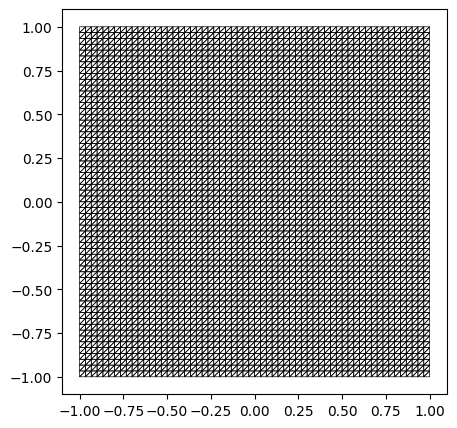

In [2]:
domain2d = (reader.dgf, "triangle.dgf")

# specify dimgrid since it cannot be easily extracted from the dgf file
aluView = leafGridView(domain2d, dimgrid=2)
aluView.plot(figsize=(5,5))

There is also a `reader.gmsh` option allowing previously stored `gmsh` files to be
read.

.. index:: Grid construction; gmsh (from Python)

## 3D examples (using GMsh)
In this example we use **pygmsh** to construct a tetrahedral mesh and solve a
simple Laplace problem

In [3]:

# The following code is taken from the **pygmsh** homepage
try:
    import pygmsh
    with pygmsh.geo.Geometry() as geom:
        poly = geom.add_polygon([
              [ 0.0,  0.5, 0.0], [-0.1,  0.1, 0.0], [-0.5,  0.0, 0.0],
              [-0.1, -0.1, 0.0], [ 0.0, -0.5, 0.0], [ 0.1, -0.1, 0.0],
              [ 0.5,  0.0, 0.0], [ 0.1,  0.1, 0.0] ], mesh_size=0.05)
        geom.twist(
            poly,
            translation_axis=[0, 0, 1], rotation_axis=[0, 0, 1], point_on_axis=[0, 0, 0],
            angle=numpy.pi / 3,
        )
        mesh = geom.generate_mesh(verbose=False)

    points, cells = mesh.points, mesh.cells_dict
    domain3d = {"vertices":points.astype("float"), "simplices":cells["tetra"]}
except ImportError: # pygmsh not installed - use a simple cartesian domain
    print("pygmsh module not found using a simple Cartesian domain - ignored")
    from dune.grid import cartesianDomain
    domain3d = cartesianDomain([-0.25,-0.25,0],[0.25,0.25,1],[30,30,60])

gridView3d  = leafGridView(domain3d)
space3d = solutionSpace(gridView3d, order=1)

u = TrialFunction(space3d)
v = TestFunction(space3d)
x = SpatialCoordinate(space3d)
scheme3d = solutionScheme((inner(grad(u),grad(v))+inner(u,v))*dx ==
                        conditional(dot(x,x)<.01,100,0)*v*dx,
                        solver='cg')

uh3d = space3d.interpolate([0],name="solution")
scheme3d.solve(target=uh3d)
# note: plotting with matplotlib not yet available for 3d grids
gridView3d.writeVTK('3dexample', pointdata=[uh3d],
                    outputType=OutputType.appendedraw)

![3d laplace problem](figures/3dexample.png)


.. index:: Grid construction; gmsh2dgf (from Python)

## Converting gmsh to DGF

Using the above convenient way of generating grids
in Python we can then store those as DGF and add boundary
ids for description of more complicated boundaries or
parameters for vertices or cells. Use `gmsh2DGF` from
[gmsh2dgf](gmsh2dgf_nb.ipynb) to convert the above `points` and `cells`


In [4]:
from gmsh2dgf import gmsh2DGF
dgf = gmsh2DGF(points, cells)
with open ("3dmesh.dgf", "w") as file:
    file.write(dgf)


## 1D example
We can also do 1D

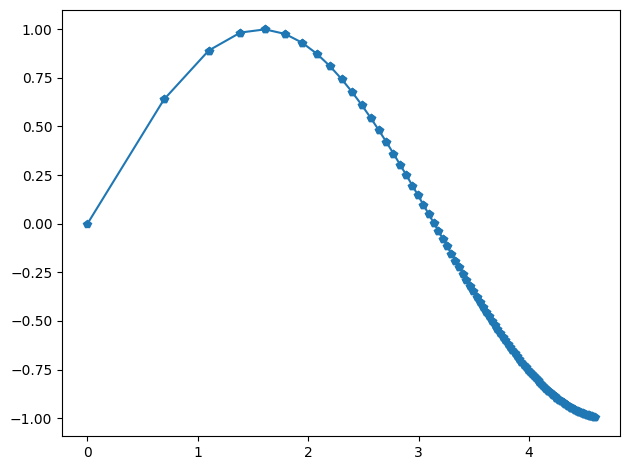

In [5]:
from dune.grid import onedGrid
v = [numpy.log(i) for i in range(1,100)]
e = [(i,i+1) for i in range(1,len(v))]
g = onedGrid(constructor={"vertices":v, "simplices":e})
s = solutionSpace(g)
x = SpatialCoordinate(s)
u = s.interpolate(sin(x[0]), name="u")
u.plot()

pyplot can very easily be used in 1d:
pyplot.plot(g.tessellate()[0], u.pointData(), '-p')